# 1. Imports

In [1]:
import numpy as np
from python.sql_module import SQL
from python.read_module import ReadData
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# 2. VARIABLES

In [2]:
_CONFIG_PATH = 'config.yaml'
_READER = ReadData(_CONFIG_PATH)

# 3. DATA

In [3]:
dim_calendar = _READER.read_data(table_name='gold_sku.dim_calendar')
fact_sales_agg_daily = _READER.read_data(table_name='gold_sku.fact_sales_agg_daily')
fact_sales_agg_daily_calendar = fact_sales_agg_daily.merge(
    dim_calendar,
    on='date'
)

fact_sales_agg_daily_calendar['year'] = [x.year for x in fact_sales_agg_daily_calendar['date']]

# 4. DATA QUALITY CHECKS

## 4.1 fact_sales_agg_daily

In [4]:
assert fact_sales_agg_daily.shape[0] == 1826
assert int(fact_sales_agg_daily['revenue'].sum()) == 644115980

# 5. FUNCTIONS 

## 5.1 Rolling Mean Function

In [5]:
def calculate_rolling_mean(
        df: pd.DataFrame,
        rolling_window: int,
        min_occurences: int,
        agg_column: str,
        group_by_column: str = None,
) -> pd.DataFrame:
    """
    Function that calculates the moving average over the specified rolling window and column.
    Params:

            df: DataFrame for which the column should be calculated.
            rolling_window: The window for which the moving average should be calculated.
            min_occurences: Minimal number of occurences in the rollig_window for the average to be calculated.
            agg_column: Name of the column for which the average should be calculated.
            group_by_column: Name of the column of the group for which the average should be calculated. Must be a datetime column.

    """
    if group_by_column:
        data_frame = pd.DataFrame(df.groupby(
            group_by_column
        )[agg_column].sum().rolling(rolling_window, min_occurences, center=True).mean()).rename(
            columns={agg_column:f'{agg_column}_{rolling_window}_d_avg'}
        )

        merged_frame = df.merge(
            data_frame,
            how='left',
            on=group_by_column
        )
        return merged_frame
        
    

## 5.2 Slope and Intercept

In [ ]:
def calculate_slope_and_intercept(
        df: pd.DataFrame,
        x: str,
        y: str
):
    """
    Function that calculates the slope and intercept for given parameters.
    """
    y = df[y].dropna()
    locs = y.index
    x = df[x].loc[locs]
    return np.polyfit(x,y,1)

# 6. Data Viz

# 6.1 Whole level of the shop.

In [7]:
fact_sales_agg_daily = calculate_rolling_mean(fact_sales_agg_daily, 7, 7, 'revenue', group_by_column='date')
fact_sales_agg_daily = calculate_rolling_mean(fact_sales_agg_daily, 30, 30, 'revenue', group_by_column='date')
fact_sales_agg_daily = fact_sales_agg_daily.merge(
    dim_calendar[['date','days_since_start']],
    on='date'
)

In [8]:
slope_reg, intercept_reg = calculate_slope_and_intercept(
    fact_sales_agg_daily,
    x = 'days_since_start',
    y = 'revenue'
)

In [9]:
regular_line = slope_reg * fact_sales_agg_daily['days_since_start'] + intercept_reg

### 6.1.1 Daily Level.

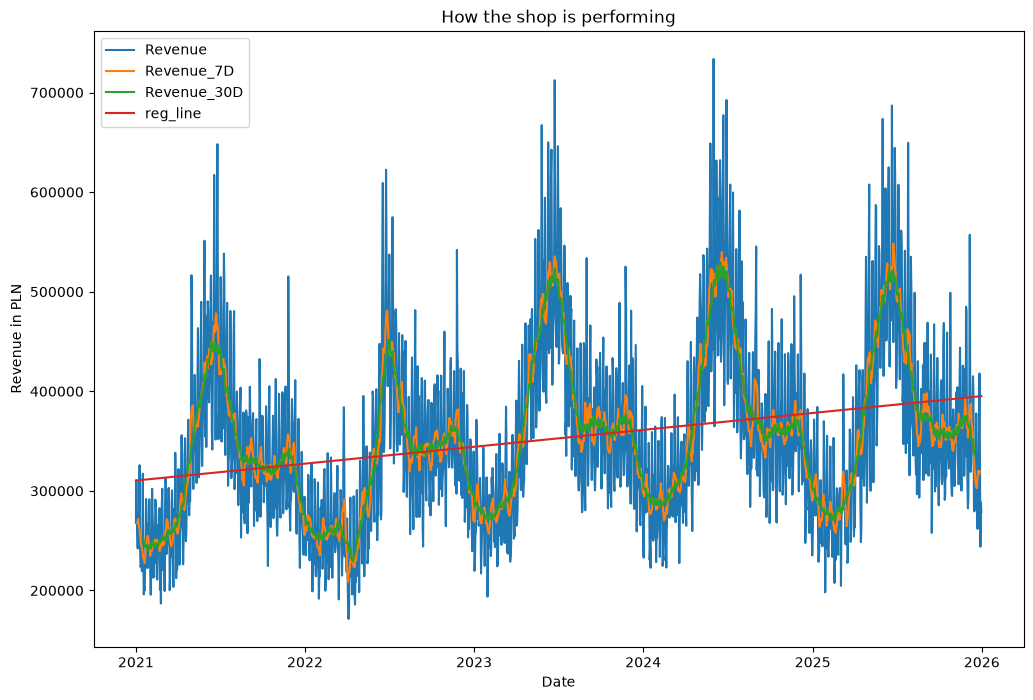

In [10]:
plt.figure(figsize=(12,8))
sns.lineplot(fact_sales_agg_daily, x='date', y='revenue', label = 'Revenue')
sns.lineplot(fact_sales_agg_daily, x='date', y = 'revenue_7_d_avg', label = 'Revenue_7D')
sns.lineplot(fact_sales_agg_daily, x='date', y = 'revenue_30_d_avg', label = 'Revenue_30D')
plt.plot(fact_sales_agg_daily['date'], regular_line, label = 'reg_line')
plt.legend();
plt.ylabel("Revenue in PLN");
plt.xlabel("Date");
plt.title("How the shop is performing");

### 6.1.2 Yearly Level

Text(0.5, 0, 'Year')

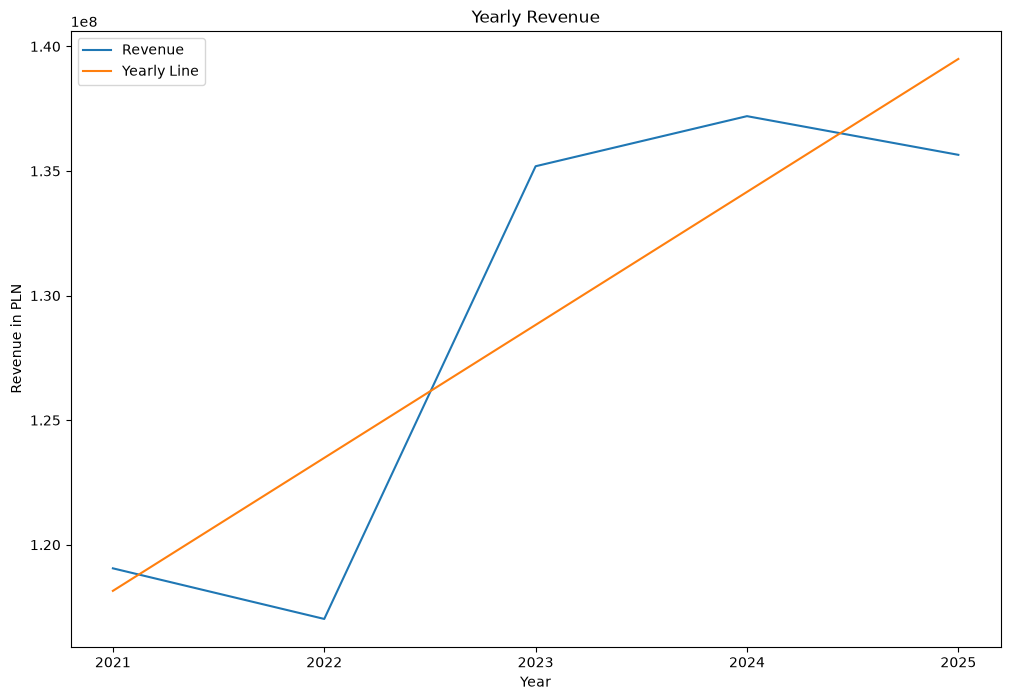

In [11]:
yearly_lvl = fact_sales_agg_daily_calendar.groupby(
    'year'
)['revenue'].sum().reset_index()

yearly_lvl['_len'] = np.arange(len(yearly_lvl))
yearly_slope, yearly_intercept = calculate_slope_and_intercept(
    yearly_lvl,
    x='_len',
    y = 'revenue'
)

yearly_line = yearly_slope * yearly_lvl['_len'] + yearly_intercept

plt.figure(figsize=(12,8))
ax = sns.lineplot(yearly_lvl, x='year', y='revenue', label = "Revenue")
plt.plot(yearly_lvl['year'], yearly_line, label="Yearly Line")
ax.set_xticks(np.array([2021, 2022 ,2023 ,2024, 2025]));
plt.legend();
plt.title("Yearly Revenue");
plt.ylabel("Revenue in PLN");
plt.xlabel("Year")